In [63]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
import numpy as np
import h5py
import re

# root = "/home/lwu/work/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/refining/data_slash_results/"
# filename = root + 'archs4_gene_human_v2.1_normalized_LW20230126.h5'

filename = "/home/lwu/ARCHS4/Tests/top_10_genesets_per_category/test_cases/test_h5df_data.hdf5"

with h5py.File(filename, 'r') as f:
    qn_matrix = f['data/qn_matrix'][:]
    gene_names = f['meta/genes/all_gene_names'][:]
    category_names = f['meta/biosamples/category'][:]

category_names = [x.decode('UTF-8') for x in category_names]
gene_names = [x.decode('UTF-8') for x in gene_names]

# Variables 
category_dict  = {
    "Cardiovascular System" : ["Heart", "Atrium", "Cardiac Muscle Fiber", 
                               "Pericardium", "Valve", "Ventricle",
                               "HUVEC"], 
    
    "Connective Tissue" : ["Adipose", "Adipocyte", "Myofibroblast", "Osteoblast", "Stromal Cell", 
                           "MG63", "K562", "Bone Marrow", "Chondrocyte", "HT1080", "NHDF"],

    "Digestive System": ["HCT116", "HT29", "RKO", "Colon", "Colonic Muscosa", "Intestinal Epithelial Cell", 
                         "Small Intestine", "Liver", "Hepatic Stellate Cell", "Hepatocyte", "Primary Liver Cell",
                         "HEPG2", "Alpha Cell", "Beta Cell", "Pancreatic Islet", 
                         "GSE81547", "PANC1", "Gastric Epithelial Cell", "Esophagus"],
    
    "Immune System" : ["Granulocyte", "Neutrophil", "Blymphocyte", "Plasma Cell", "Plasmacytoid Dendritic Cell", 
                       "Tlymphocyte", "GSM2679484", "JURKAT", "MT4", "NALM6", "REH", "RPMI8226", "Alveolar", 
                       "Dendritic", "Kupffer", "Macrophage", "Macroglia",  "THP1", "U937", "JEG3", "Thymus", 
                       "Thymocyte", "Spleen"],
    
    "Integumentary System" : ["Skin", "Basal Cell", "Fibroblast", "Hair Follicle", "Keratinocyte", "Melanocyte",
                              "A431", "HACAT", "HNSCC"], 
    
    "Muscular System" : ["Skeletal Muscle", "Myoblast", "Airway Smooth Muscle", "Respiratory Smooth Muscle", 
                         "Vascular Smooth Muscle", "LHCNM2"], 
    
    "Nervous System" : ["Brain", "DAOY", "IMR32", "SKNSH", "Astrocyte", "Cerebellum", "Cerebral Cortex", 
                        "Hypothalamus", "Medula", "Midbrain", "Neuron", "Oligodendrocyte", "Pons", "Spinal Cord", 
                        "Thalamus", "Retina", "Motor Neuron", "Sensory Neuron"], 
    
    "Respiratory System" : ["Lung", "Lung Epithelial", "A549", "H1299", "IMR90", "MRC5", "NCIH460", "NHBE", 
                            "Trachea"], 
    
    "Urogenital System" : ["Breast", "Mammary Gland", "MCF7", "MCF10", "MDAMB231", "MDAMB468", "SKBR3", "T47D", 
                           "HELA", "Kidney", "Podocyte", "Renal Cortex", "293F", "FLPIN TREX 293", "HEK293", "C42", 
                           "DU145", "LNCAP", "PC3", "Ovary", "Granulosa", "Oocyte", "ES2", "SKOV3", "Testis"]
}


# folder = "/home/lwu/ARCHS4/Tests/Check If Biosample Categorys Align With Genesets/"
# filename = folder + "h.c1.c2.all.v7.5.1.symbols.gmt"

filename = "/home/lwu/ARCHS4/Tests/top_10_genesets_per_category/test_cases/test_geneset.gmt"

In [54]:
qn_matrix

array([[ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10],
       [11, 12, 13, 14, 15, 16, 17, 18, 19, 20],
       [21, 22, 23, 24, 25, 26, 27, 28, 29, 30],
       [31, 32, 33, 34, 35, 36, 37, 38, 39, 40],
       [41, 42, 43, 44, 45, 46, 47, 48, 49, 50]])

In [56]:
row_totals = np.sum(qn_matrix, axis=1)
col_totals = np.sum(qn_matrix, axis=0)
total = np.sum(qn_matrix)
expected = np.outer(row_totals, col_totals) / total
print("**Expected Matrix**")
print(expected)
print()
print()

observed = qn_matrix
normalized = observed / expected 
print("**Normalized Matrix**")
print(normalized)

**Expected Matrix**
[[ 4.52941176  4.74509804  4.96078431  5.17647059  5.39215686  5.60784314
   5.82352941  6.03921569  6.25490196  6.47058824]
 [12.76470588 13.37254902 13.98039216 14.58823529 15.19607843 15.80392157
  16.41176471 17.01960784 17.62745098 18.23529412]
 [21.         22.         23.         24.         25.         26.
  27.         28.         29.         30.        ]
 [29.23529412 30.62745098 32.01960784 33.41176471 34.80392157 36.19607843
  37.58823529 38.98039216 40.37254902 41.76470588]
 [37.47058824 39.25490196 41.03921569 42.82352941 44.60784314 46.39215686
  48.17647059 49.96078431 51.74509804 53.52941176]]


**Normalized Matrix**
[[0.22077922 0.4214876  0.60474308 0.77272727 0.92727273 1.06993007
  1.2020202  1.32467532 1.43887147 1.54545455]
 [0.86175115 0.8973607  0.92987377 0.95967742 0.98709677 1.01240695
  1.03584229 1.05760369 1.07786429 1.09677419]
 [1.         1.         1.         1.         1.         1.
  1.         1.         1.         1.        ]
 

In [61]:
log_normalized = np.log2(normalized)
print("**Log-Normalized Matrix**")
print(log_normalized)
print()
print()

pos_log_normalized = np.log2(normalized + 1)
print("**Positive Log-Normalized Matrix**")
print(pos_log_normalized)

**Log-Normalized Matrix**
[[-2.1793237  -1.2464379  -0.72560573 -0.37196878 -0.10893437  0.09751651
   0.26546114  0.4056388   0.52493773  0.62803122]
 [-0.21465677 -0.15624009 -0.10489321 -0.05937855 -0.01873656  0.01778931
   0.05080437  0.08079911  0.10817555  0.13326653]
 [ 0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.        ]
 [ 0.08455711  0.0632466   0.04351039  0.02517856  0.00810505 -0.00783649
  -0.02275591 -0.03674919 -0.04990055 -0.06228428]
 [ 0.12986528  0.09751651  0.0673335   0.03909982  0.01262761 -0.01224706
  -0.03566795 -0.05776172 -0.07864045 -0.0984037 ]]


**Positive Log-Normalized Matrix**
[[0.28780231 0.50740152 0.68234234 0.8259706  0.94656074 1.04958203
  1.1388277  1.21702924 1.28621373 1.3479233 ]
 [0.89666025 0.92399397 0.94850649 0.97061619 0.99066214 1.00892208
  1.02562581 1.04096513 1.05510143 1.0681715 ]
 [1.         1.         1.         1.         1.         1.
  1.         1.         1.   

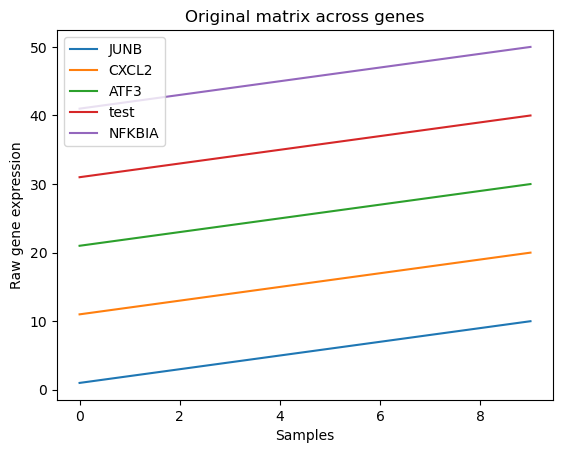

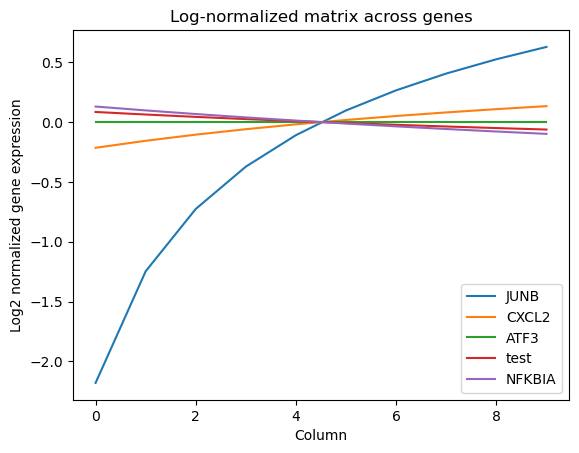

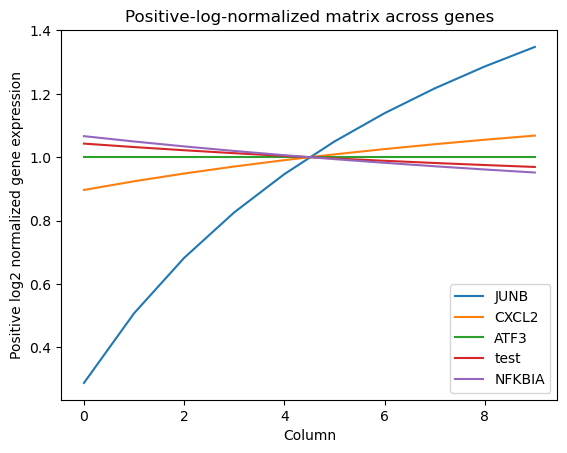

In [66]:
# plot original matrix across rows
fig, ax = plt.subplots()
for i, name in enumerate(gene_names):
    ax.plot(qn_matrix[i,:], label=name)
ax.legend()
ax.set_xlabel("Samples")
ax.set_ylabel("Raw gene expression")
ax.set_title("Original matrix across genes")
plt.show()

# plot log_normalized matrix across rows
fig, ax = plt.subplots()
for i, name in enumerate(gene_names):
    ax.plot(log_normalized[i,:], label=name)
ax.legend()
ax.set_xlabel("Column")
ax.set_ylabel("Log2 normalized gene expression")
ax.set_title("Log-normalized matrix across genes")
plt.show()

# plot pos_log_normalized matrix across rows
fig, ax = plt.subplots()
for i, name in enumerate(gene_names):
    ax.plot(pos_log_normalized[i,:], label=name)
ax.legend()
ax.set_xlabel("Column")
ax.set_ylabel("Positive log2 normalized gene expression")
ax.set_title("Positive-log-normalized matrix across genes")
plt.show()


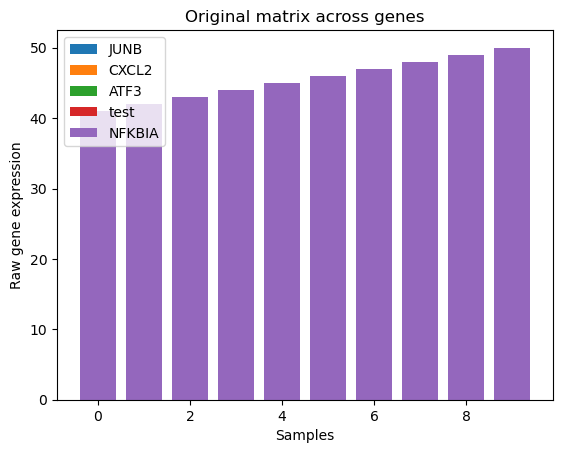

In [68]:
fig, ax = plt.subplots()
for i, name in enumerate(gene_names):
    ax.bar(range(qn_matrix.shape[1]), qn_matrix[i,:], label=name)
ax.legend()
ax.set_xlabel("Samples")
ax.set_ylabel("Raw gene expression")
ax.set_title("Original matrix across genes")
plt.show()


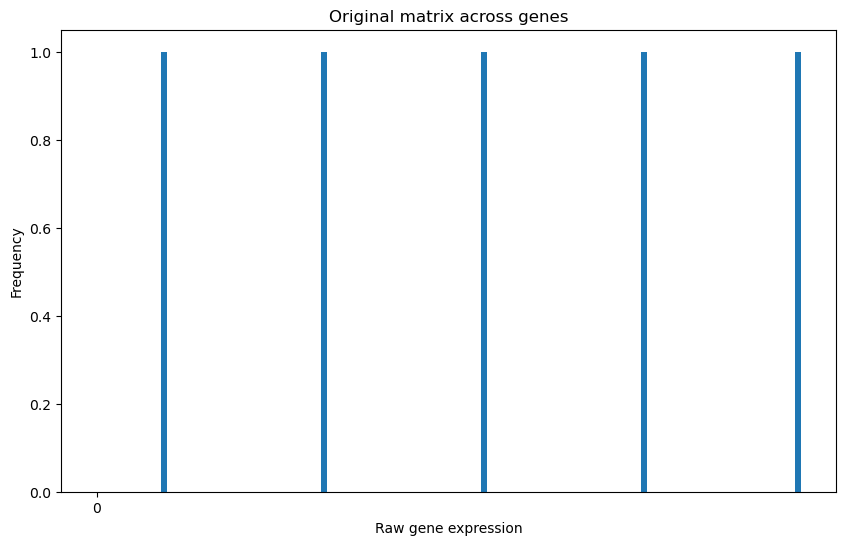

In [74]:
import numpy as np
import matplotlib.pyplot as plt

qn_matrix = np.array([[ 0, 1, 2, 3, 4],
                      [ 5, 6, 7, 8, 9],
                      [10, 11, 12, 13, 14],
                      [15, 16, 17, 18, 19],
                      [20, 21, 22, 23, 24]])

gene_names = ["gene1", "gene2", "gene3", "gene4", "gene5"]

# Calculate the row sums
row_sums = qn_matrix.sum(axis=1)

# Convert row_sums to integer values
row_sums = row_sums.astype(int)

# Plot the histogram
plt.figure(figsize=(10, 6))
plt.hist(row_sums, bins=range(0, row_sums.max()+1))

plt.title('Original matrix across genes')
plt.xlabel('Raw gene expression')
plt.ylabel('Frequency')

plt.xticks(np.arange(0, row_sums.max()+1, 1000), np.arange(0, row_sums.max()+1, 1000))

plt.show()


In [71]:
row_sums

array([ 10,  35,  60,  85, 110])

In [76]:
filename = "/home/lwu/ARCHS4/Tests/top_10_genesets_per_category/test_cases/test_h5df_data.hdf5"
file = h5py.File(filename, "a")

# write the list to the dataset in the pathway "meta/biosamples/"
file["data/logOE_matrix"] = pos_log_normalized

# close the h5py file
file.close()
